# Speed Prediction — Baseline Model (원본 컬럼)

매칭된 링크의 T-data 평균속도를 머신러닝으로 얼마나 예측할 수 있는지 검증하는 첫 단계입니다.

**이번 단계의 범위**: 시간 순환 인코딩, 강수×경사 상호작용 같은 파생 피처는 아직 만들지 않습니다. **최종 결합 테이블에 이미 있는 원본 컬럼만** 사용해 베이스라인을 먼저 잡고, 그 결과를 보고 어떤 파생 피처가 필요한지 다음 단계에서 하나씩 추가/검증합니다.

**입력**: `data/processed/seoul_link_speed_dem_weather_merged.csv` (2,991,475행)
**타깃**: `평균속도`

**검증 전략 미리보기**: T-data 매칭은 하나의 소스 행이 평균 3.57개의 형제 링크(LINK_ID 앞 8자리 공유)에 같은 속도값을 broadcast하는 구조([data/README.md의 T-data LINK_ID 매칭](../data/README.md#t-data-link_id-매칭) 참고)입니다. 형제 링크가 train/test에 무작위로 흩어지면 사실상 정답을 이미 본 상태로 채점하는 셈이라 성능이 부풀려집니다. 이 노트북은 `LINK_ID` 앞 8자리를 기준으로 그룹 분할을 하고, 랜덤 분할과 직접 비교해 그 효과를 정량적으로 보여줍니다.

In [1]:
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split

# Jupyter 실행 위치가 notebooks/ 폴더라고 가정합니다 (jupyter lab/notebook 기본 동작).
PROJECT_ROOT = Path.cwd().parent
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
DOCS_FIGURES_DIR = PROJECT_ROOT / "docs" / "figures" / "model"
DOCS_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

INPUT_PATH = PROCESSED_DATA_DIR / "seoul_link_speed_dem_weather_merged.csv"

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

RANDOM_STATE = 42

# notebooks/10_eda_report.ipynb와 동일 계열 팔레트를 재사용해 시각적 일관성을 유지합니다.
COLORS = {
    "primary": "#4C78A8",
    "warn": "#E45756",
    "bar": "#59A14F",
    "line": "#2F4B7C",
    "accent": "#F28E2B",
}

## 1. 사용할 원본 컬럼

최종 테이블의 컬럼 중 아래 기준으로 골랐습니다.

**피처로 사용**

| 유형 | 컬럼 |
| --- | --- |
| 수치형 | `LANES`, `MAX_SPD`, `LENGTH`, `시간코드`, `elev_start_m`, `elev_mid_m`, `elev_end_m`, `elev_mean_m`, `elev_min_m`, `elev_max_m`, `elev_delta_m`, `slope_pct`, `abs_slope_pct`, `dem_sample_count`, `precip_mm` |
| 범주형 | `ROAD_RANK`, `ROAD_TYPE`, `ROAD_USE`, `MULTI_LINK`, `CONNECT`, `REST_VEH`, `REST_W`, `REST_H`, `C-ITS`, `도로방향구분코드`, `도로구분코드`, `요일코드(1~7:일~토)`, `요일그룹코드(01:주중/02:주말)`, `첨두시구분(T1/T2/T3:오전/낮/오후)` |

**제외 (이유)**

| 컬럼 | 제외 이유 |
| --- | --- |
| `LINK_ID`, `F_NODE`, `T_NODE`, `ROAD_NO`, `ROAD_NAME`, `도로명`, `시작노드명`, `종료노드명` | 고카디널리티 식별자/텍스트 — 그대로 넣으면 도로를 암기하는 과적합 |
| `도로코드`(485종), `구간순서`(44종) | 카디널리티가 낮지 않고 사실상 위치 식별자에 가까움(사전 확인 결과) |
| `도로방향구분명`, `도로구분명` | 이미 쓰는 코드값(`도로방향구분코드`, `도로구분코드`)과 1:1 대응하는 라벨 텍스트, 중복 |
| `UPDATEDATE`, `REMARK`, `HIST_TYPE`, `HISTREMARK` | 메타데이터, 예측과 무관 |
| `match_method`, `broadcast_source_link_ids`, `broadcast_source_count`, `broadcast_speed_std` | **매칭 생성 과정의 산물** — 타깃이 어떻게 만들어졌는지에 대한 정보라 유출 위험 |
| `tm`, `기준일`, `시간대설명` | `시간코드`/요일코드로 이미 표현되거나, 특정 날짜를 암기하는 과적합 위험 |
| `radar_raw_value` | `precip_mm`으로 이미 정제된 원본값, 중복 |

`LINK_ID`는 피처로는 쓰지 않지만, 아래 검증 전략에서 그룹 분할 키를 만드는 데만 사용합니다.

In [2]:
NUMERIC_COLS = [
    "LANES", "MAX_SPD", "LENGTH", "시간코드",
    "elev_start_m", "elev_mid_m", "elev_end_m", "elev_mean_m", "elev_min_m", "elev_max_m", "elev_delta_m",
    "slope_pct", "abs_slope_pct", "dem_sample_count", "precip_mm",
]
CATEGORICAL_COLS = [
    "ROAD_RANK", "ROAD_TYPE", "ROAD_USE", "MULTI_LINK", "CONNECT",
    "REST_VEH", "REST_W", "REST_H", "C-ITS",
    "도로방향구분코드", "도로구분코드",
    "요일코드(1~7:일~토)", "요일그룹코드(01:주중/02:주말)",
    "첨두시구분(T1/T2/T3:오전/낮/오후)",
]
TARGET = "평균속도"
GROUP_SOURCE_COL = "LINK_ID"

usecols = NUMERIC_COLS + CATEGORICAL_COLS + [TARGET, GROUP_SOURCE_COL]
dtype_map = {col: str for col in CATEGORICAL_COLS}
dtype_map[GROUP_SOURCE_COL] = str

df = pd.read_csv(INPUT_PATH, usecols=usecols, dtype=dtype_map, encoding="utf-8-sig")

for col in NUMERIC_COLS + [TARGET]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# LightGBM은 컬럼명에 JSON 특수문자(괄호/콜론/슬래시 등)를 허용하지 않아
# 해당 원본 컬럼만 모델링용 안전한 이름으로 바꿉니다(의미는 동일, 값은 그대로).
RENAME_MAP = {
    "요일코드(1~7:일~토)": "dow_code",
    "요일그룹코드(01:주중/02:주말)": "dow_group_code",
    "첨두시구분(T1/T2/T3:오전/낮/오후)": "peak_period",
    "C-ITS": "c_its",
}
df = df.rename(columns=RENAME_MAP)
NUMERIC_COLS = [RENAME_MAP.get(c, c) for c in NUMERIC_COLS]
CATEGORICAL_COLS = [RENAME_MAP.get(c, c) for c in CATEGORICAL_COLS]

print("행 수:", len(df))
print("컬럼 수:", df.shape[1])
df.head()

행 수: 2991475
컬럼 수: 31


,시간코드,peak_period,도로방향구분코드,평균속도,dow_code,dow_group_code,도로구분코드,LINK_ID,LANES,ROAD_RANK,...,elev_mid_m,elev_end_m,elev_mean_m,elev_min_m,elev_max_m,elev_delta_m,slope_pct,abs_slope_pct,dem_sample_count,precip_mm
0,2,N,1,29.15,3,1,4,1080012200,1,104,...,119.716469,102.827942,117.996199,102.827942,128.456451,-25.628510,-8.954402,8.954402,5,0.0
1,2,N,1,13.55,3,1,4,1080012800,2,104,...,46.192207,43.298622,46.965897,43.298622,49.753483,-6.454861,-3.735279,3.735279,5,0.0
2,2,N,2,26.81,3,1,4,1080012700,2,104,...,41.913624,41.913624,41.913624,41.913624,41.913624,0.000000,0.000000,0.000000,5,0.0
3,2,N,2,40.97,3,1,4,1080012100,1,104,...,51.283154,51.283154,50.671285,49.753483,51.283154,1.529671,2.949274,2.949274,5,0.0
4,2,N,1,37.23,3,1,5,1230019500,1,104,...,27.893988,27.893988,26.881398,25.362513,27.893988,2.531475,4.637286,4.637286,5,0.0


## 2. 결측치 확인 및 전처리

(위 표의 `요일코드(1~7:일~토)` -> `dow_code`, `요일그룹코드(01:주중/02:주말)` -> `dow_group_code`, `첨두시구분(T1/T2/T3:오전/낮/오후)` -> `peak_period`, `C-ITS` -> `c_its`로 컬럼명만 바뀌었고 값과 의미는 동일합니다.)

In [3]:
missing = df[NUMERIC_COLS + CATEGORICAL_COLS + [TARGET]].isna().sum()
missing = missing[missing > 0]
print("결측 존재 컬럼:")
print(missing if len(missing) else "없음")

before = len(df)
df = df.dropna(subset=[TARGET] + NUMERIC_COLS)
print(f"결측 제거: {before}행 -> {len(df)}행")

for col in CATEGORICAL_COLS:
    df[col] = df[col].astype("category")

# LINK_ID 앞 8자리 = T-data 매칭 진단에서 확인된 '같은 물리적 도로 구간'을 공유하는 그룹 키.
# 피처로는 쓰지 않고, 아래 그룹 분할에만 사용합니다.
df["link_group"] = df[GROUP_SOURCE_COL].str[:8]
print("고유 link_group 수:", df["link_group"].nunique())

결측 존재 컬럼:
없음
결측 제거: 2991475행 -> 2991475행


고유 link_group 수: 4449


## 3. 검증 전략: 그룹 분할 vs 랜덤 분할

`link_group`(LINK_ID 앞 8자리) 단위로 80/20 분할합니다. 같은 그룹에 속한 형제 링크는 항상 train 또는 test 중 한쪽에만 속하도록 강제해, broadcast로 인한 정답 유출을 막습니다.

비교를 위해 같은 조건(같은 랜덤시드, 같은 비율)으로 **일반 랜덤 분할**도 하나 만들어두고, 5번에서 두 분할로 학습한 모델의 성능을 직접 비교합니다.

In [4]:
FEATURE_COLS = NUMERIC_COLS + CATEGORICAL_COLS
X = df[FEATURE_COLS]
y = df[TARGET]
groups = df["link_group"]

group_splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
group_train_idx, group_test_idx = next(group_splitter.split(X, y, groups))

X_train, X_test = X.iloc[group_train_idx], X.iloc[group_test_idx]
y_train, y_test = y.iloc[group_train_idx], y.iloc[group_test_idx]

overlap = set(groups.iloc[group_train_idx]) & set(groups.iloc[group_test_idx])
print("그룹 분할 train/test 행 수:", len(X_train), len(X_test))
print("train/test 간 겹치는 link_group 수:", len(overlap), "(0이어야 정상)")

X_train_rand, X_test_rand, y_train_rand, y_test_rand = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("랜덤 분할 train/test 행 수:", len(X_train_rand), len(X_test_rand))

그룹 분할 train/test 행 수: 2389757 601718
train/test 간 겹치는 link_group 수: 0 (0이어야 정상)


랜덤 분할 train/test 행 수: 2393180 598295


## 4. 베이스라인 모델 (그룹 분할 기준)

원본 컬럼으로 만든 LightGBM이 얼마나 잘하는지 판단하려면 비교 기준이 필요합니다. 단순한 것부터 순서대로 만듭니다.

1. **전체 평균**: 아무 피처도 안 쓰고 train 평균속도로만 예측
2. **MAX_SPD 선형회귀**: EDA에서 상관계수가 가장 높았던(0.379) 변수 하나만 사용
3. **ROAD_RANK별 평균**: 도로등급 7종의 train 평균속도로 예측
4. **LightGBM (원본 피처 전체)**: 이번 단계의 본 모델

In [5]:
def evaluate(y_true, y_pred, name):
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {"model": name, "rmse": rmse, "mae": mae, "r2": r2}


results = []

# 1) 전체 평균 (피처는 무시하고 shape만 맞춤)
dummy = DummyRegressor(strategy="mean").fit(X_train[["LENGTH"]], y_train)
pred = dummy.predict(X_test[["LENGTH"]])
results.append(evaluate(y_test, pred, "전체 평균"))

# 2) MAX_SPD 선형회귀
lin = LinearRegression().fit(X_train[["MAX_SPD"]], y_train)
pred = lin.predict(X_test[["MAX_SPD"]])
results.append(evaluate(y_test, pred, "MAX_SPD 선형회귀"))

# 3) ROAD_RANK별 평균
rank_mean = y_train.groupby(X_train["ROAD_RANK"], observed=True).mean()
pred = X_test["ROAD_RANK"].map(rank_mean).fillna(y_train.mean())
results.append(evaluate(y_test, pred, "ROAD_RANK별 평균"))

# 4) LightGBM (원본 피처 전체, 그룹 분할)
lgb_model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=63,
    random_state=RANDOM_STATE,
    verbosity=-1,
)
lgb_model.fit(X_train, y_train, categorical_feature=CATEGORICAL_COLS)
pred_lgb_group = lgb_model.predict(X_test)
results.append(evaluate(y_test, pred_lgb_group, "LightGBM (그룹 분할)"))

results_df = pd.DataFrame(results)
results_df

,model,rmse,mae,r2
0,전체 평균,9.414977,6.213798,-0.000982
1,MAX_SPD 선형회귀,8.598385,5.949068,0.165125
2,ROAD_RANK별 평균,7.649117,5.675448,0.339291
3,LightGBM (그룹 분할),6.151543,4.529821,0.572677


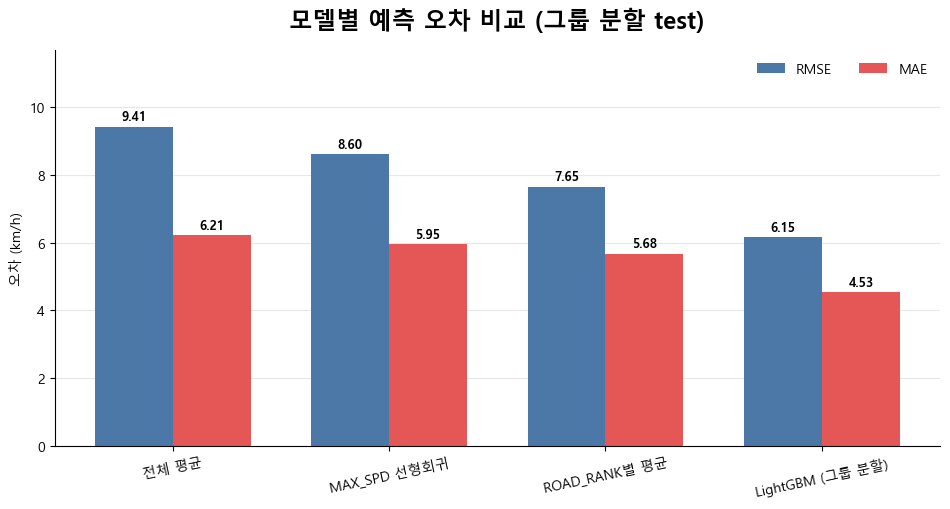

저장: C:\Users\ejjun\Desktop\seoul-eco-routing\docs\figures\model\01_model_comparison.png


In [6]:
labels = results_df["model"].tolist()
x = range(len(labels))
width = 0.36

fig, ax = plt.subplots(figsize=(9.6, 5.2))
ax.bar([i - width / 2 for i in x], results_df["rmse"], width, label="RMSE", color=COLORS["primary"])
ax.bar([i + width / 2 for i in x], results_df["mae"], width, label="MAE", color=COLORS["warn"])
ax.set_xticks(list(x), labels, rotation=12)
ax.set_title("모델별 예측 오차 비교 (그룹 분할 test)", fontsize=17, fontweight="bold", pad=16)
ax.set_ylabel("오차 (km/h)")
ax.legend(frameon=False, ncols=2, loc="upper right")

for patch in ax.patches:
    height = patch.get_height()
    ax.text(patch.get_x() + patch.get_width() / 2, height + 0.1, f"{height:.2f}",
            ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="#E5E7EB", linewidth=0.8)
ax.set_axisbelow(True)
top = ax.get_ylim()[1]
ax.set_ylim(0, top * 1.18)
fig.tight_layout()
fig.savefig(DOCS_FIGURES_DIR / "01_model_comparison.png", dpi=220, bbox_inches="tight")
plt.show()
print("저장:", DOCS_FIGURES_DIR / "01_model_comparison.png")

## 5. 랜덤 분할과 비교: 그룹 분할이 정말 필요한가

같은 LightGBM 설정을 **일반 랜덤 분할**(3번에서 만든 `X_train_rand`)로도 학습해서, 그룹 분할 결과와 나란히 비교합니다. 차이가 크면 broadcast 유출이 실제로 성능을 부풀린다는 뜻입니다. (단순 베이스라인 1~3번은 개별 링크 패턴을 암기할 만큼 유연하지 않아 이 비교에서 제외했습니다.)

In [7]:
lgb_model_rand = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=63,
    random_state=RANDOM_STATE,
    verbosity=-1,
)
lgb_model_rand.fit(X_train_rand, y_train_rand, categorical_feature=CATEGORICAL_COLS)
pred_lgb_rand = lgb_model_rand.predict(X_test_rand)

split_compare = pd.DataFrame([
    evaluate(y_test, pred_lgb_group, "그룹 분할"),
    evaluate(y_test_rand, pred_lgb_rand, "랜덤 분할"),
])
split_compare

,model,rmse,mae,r2
0,그룹 분할,6.151543,4.529821,0.572677
1,랜덤 분할,5.213026,3.976965,0.668029


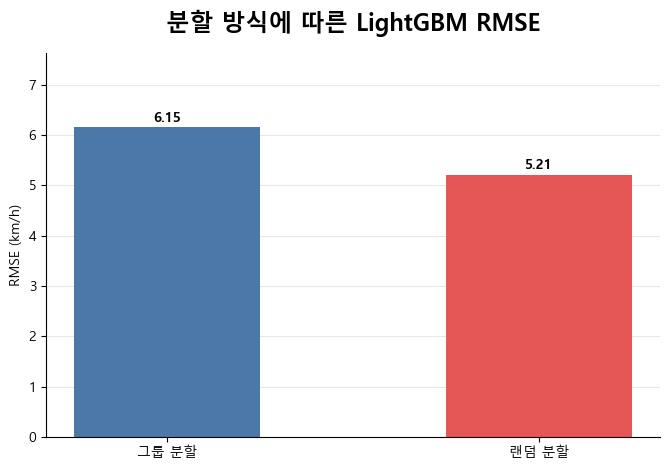

저장: C:\Users\ejjun\Desktop\seoul-eco-routing\docs\figures\model\02_split_leakage_comparison.png


In [8]:
fig, ax = plt.subplots(figsize=(6.8, 4.8))
plot_colors = [COLORS["primary"], COLORS["warn"]]
ax.bar(split_compare["model"], split_compare["rmse"], color=plot_colors, width=0.5)
ax.set_title("분할 방식에 따른 LightGBM RMSE", fontsize=17, fontweight="bold", pad=16)
ax.set_ylabel("RMSE (km/h)")

for patch in ax.patches:
    height = patch.get_height()
    ax.text(patch.get_x() + patch.get_width() / 2, height + 0.05, f"{height:.2f}",
            ha="center", va="bottom", fontsize=10, fontweight="bold")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="#E5E7EB", linewidth=0.8)
ax.set_axisbelow(True)
top = ax.get_ylim()[1]
ax.set_ylim(0, top * 1.18)
fig.tight_layout()
fig.savefig(DOCS_FIGURES_DIR / "02_split_leakage_comparison.png", dpi=220, bbox_inches="tight")
plt.show()
print("저장:", DOCS_FIGURES_DIR / "02_split_leakage_comparison.png")

## 6. 피처 중요도 (그룹 분할 LightGBM)

어떤 원본 컬럼이 실제로 예측에 기여하는지 확인합니다. 이 결과는 다음 단계에서 어떤 파생 피처를 추가할지 우선순위를 정하는 데 사용합니다.

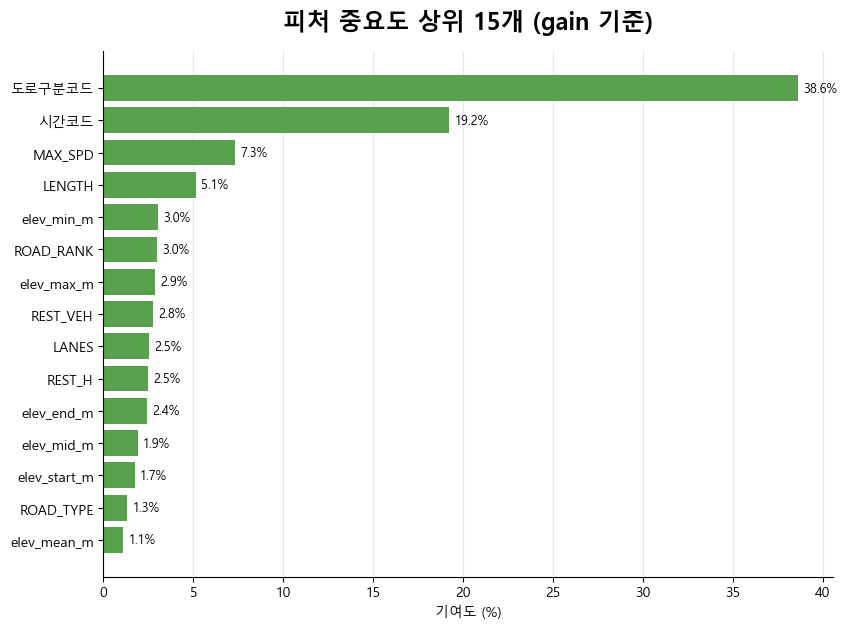

저장: C:\Users\ejjun\Desktop\seoul-eco-routing\docs\figures\model\03_feature_importance.png


,feature,gain,gain_share
25,도로구분코드,5.154466e+08,0.386276
3,시간코드,2.567301e+08,0.192394
1,MAX_SPD,9.747890e+07,0.073051
2,LENGTH,6.838223e+07,0.051246
8,elev_min_m,4.012634e+07,0.030071
15,ROAD_RANK,3.980824e+07,0.029832
9,elev_max_m,3.809235e+07,0.028546
20,REST_VEH,3.691662e+07,0.027665
0,LANES,3.370077e+07,0.025255
22,REST_H,3.273808e+07,0.024534


In [9]:
importance = pd.DataFrame({
    "feature": lgb_model.feature_name_,
    "gain": lgb_model.booster_.feature_importance(importance_type="gain"),
}).sort_values("gain", ascending=False)
importance["gain_share"] = importance["gain"] / importance["gain"].sum()

top_n = 15
plot_df = importance.head(top_n).sort_values("gain")

fig, ax = plt.subplots(figsize=(8.6, 6.4))
ax.barh(plot_df["feature"], plot_df["gain_share"] * 100, color=COLORS["bar"])
ax.set_title(f"피처 중요도 상위 {top_n}개 (gain 기준)", fontsize=17, fontweight="bold", pad=16)
ax.set_xlabel("기여도 (%)")

for patch in ax.patches:
    width = patch.get_width()
    ax.text(width + 0.3, patch.get_y() + patch.get_height() / 2, f"{width:.1f}%",
            va="center", fontsize=9)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", color="#E5E7EB", linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(DOCS_FIGURES_DIR / "03_feature_importance.png", dpi=220, bbox_inches="tight")
plt.show()
print("저장:", DOCS_FIGURES_DIR / "03_feature_importance.png")

importance.head(top_n)

## 7. 예측값 vs 실제값 (그룹 분할 test)

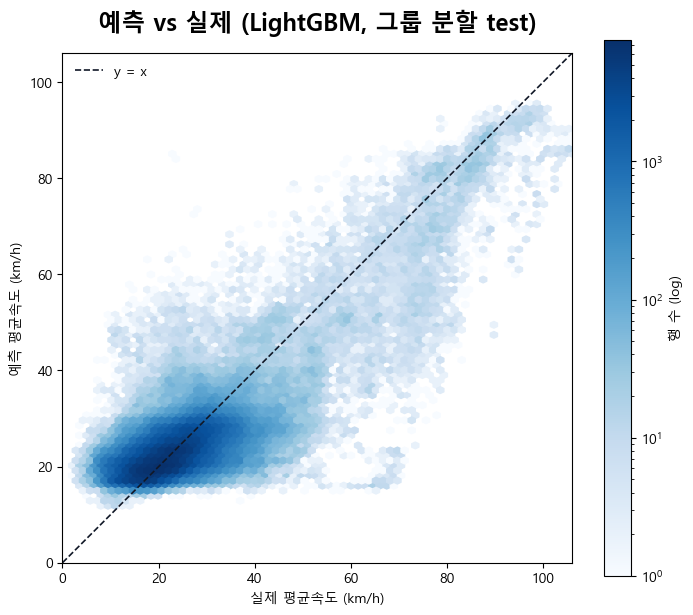

저장: C:\Users\ejjun\Desktop\seoul-eco-routing\docs\figures\model\04_predicted_vs_actual.png


In [10]:
fig, ax = plt.subplots(figsize=(7.2, 7.0))
hb = ax.hexbin(y_test, pred_lgb_group, gridsize=70, cmap="Blues", mincnt=1, bins="log")
lims = [0, max(y_test.max(), pred_lgb_group.max())]
ax.plot(lims, lims, color="#111827", linewidth=1.2, linestyle="--", label="y = x")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("실제 평균속도 (km/h)")
ax.set_ylabel("예측 평균속도 (km/h)")
ax.set_title("예측 vs 실제 (LightGBM, 그룹 분할 test)", fontsize=17, fontweight="bold", pad=16)
ax.legend(frameon=False, loc="upper left")
cb = fig.colorbar(hb, ax=ax, shrink=0.8)
cb.set_label("행 수 (log)")
ax.set_aspect("equal")
fig.tight_layout()
fig.savefig(DOCS_FIGURES_DIR / "04_predicted_vs_actual.png", dpi=220, bbox_inches="tight")
plt.show()
print("저장:", DOCS_FIGURES_DIR / "04_predicted_vs_actual.png")

## 요약

In [11]:
print("=== 모델 비교 (그룹 분할 test) ===")
print(results_df.round(3).to_string(index=False))
print()
print("=== 분할 방식 비교 (LightGBM) ===")
print(split_compare.round(3).to_string(index=False))
print()
print("=== 피처 중요도 상위 5개 ===")
print(importance.head(5)[["feature", "gain_share"]].round(4).to_string(index=False))

=== 모델 비교 (그룹 분할 test) ===
           model  rmse   mae     r2
           전체 평균 9.415 6.214 -0.001
    MAX_SPD 선형회귀 8.598 5.949  0.165
   ROAD_RANK별 평균 7.649 5.675  0.339
LightGBM (그룹 분할) 6.152 4.530  0.573

=== 분할 방식 비교 (LightGBM) ===
model  rmse   mae    r2
그룹 분할 6.152 4.530 0.573
랜덤 분할 5.213 3.977 0.668

=== 피처 중요도 상위 5개 ===
   feature  gain_share
    도로구분코드      0.3863
      시간코드      0.1924
   MAX_SPD      0.0731
    LENGTH      0.0512
elev_min_m      0.0301


이 결과는 **원본 컬럼만으로 만든 첫 베이스라인**입니다. 파생 피처(시간 순환 인코딩, 강수×첨두시 상호작용, 강수 구간화, 경사×강수 상호작용 등)는 아직 넣지 않았습니다.

**핵심 결과** (그룹 분할 test, 601,718행)

| 모델 | RMSE | MAE | R² |
| --- | --- | --- | --- |
| 전체 평균 | 9.41 | 6.21 | -0.00 |
| MAX_SPD 선형회귀 | 8.60 | 5.95 | 0.17 |
| ROAD_RANK별 평균 | 7.65 | 5.68 | 0.34 |
| **LightGBM (원본 피처 전체)** | **6.15** | **4.53** | **0.57** |

원본 컬럼만으로도 전체 평균 대비 RMSE를 35% 줄였고, EDA에서 가장 강한 단일 신호였던 MAX_SPD 선형회귀보다도 28% 더 낮은 오차를 냅니다. 다만 R² 0.57은 아직 분산의 절반 가까이를 설명하지 못한다는 뜻이라, 파생 피처로 더 개선할 여지가 있습니다.

**그룹 분할이 실제로 필요했는가**: 같은 LightGBM을 랜덤 분할로 학습하면 R²가 0.573 -> 0.668로, RMSE가 6.15 -> 5.21km/h로 눈에 띄게 좋아 보입니다. 이건 실제 예측력이 좋아진 게 아니라 broadcast 형제 링크가 train/test에 섞여 들어간 유출 효과입니다. 그룹 분할 없이 평가했다면 실제보다 약 15% 더 좋은 성능으로 착각했을 것입니다 -- 검증 전략이 실질적으로 필요했다는 게 수치로 확인됐습니다.

**피처 중요도 상위 5개**: `도로구분코드`(38.6%, T-data 자체 도로분류: 보조간선/주간선/기타/도시고속도로) > `시간코드`(19.2%) > `MAX_SPD`(7.3%) > `LENGTH`(5.1%) > `elev_min_m`(3.0%). `도로구분코드`가 MOCT_LINK의 `ROAD_RANK`(2.98%)보다 훨씬 강한 신호라는 점이 눈에 띕니다 -- EDA 단계에서는 다루지 않았던 피처인데, 원본 컬럼만으로도 가장 중요한 예측 변수로 나타났습니다. `시간코드`도 순환 인코딩 없이 정수 그대로 넣었는데 두 번째로 중요해서, 다음 단계에서 사인/코사인 인코딩을 추가하면 개선 여지가 있어 보입니다.

**다음 단계**: 이 피처 중요도 순위를 참고해 파생 피처를 하나씩 추가하면서, 매번 이 노트북과 동일한 **그룹 분할** 기준으로 RMSE/MAE가 실제로 개선되는지 확인해야 합니다(랜덤 분할로 확인하면 다시 부풀려진 착시를 보게 됩니다). 개선폭이 없는 파생 피처는 채택하지 않고, 있는 것만 남기는 방식으로 진행하면 됩니다.

이 결과는 인과관계 검증이 아니라 예측 성능 검증입니다.